# Math 32 — Lecture 32: Type II Errors — How Often Do We Miss?

Companion notebook for Lecture 32 (Standard 11: Hypothesis Testing). Every figure and number in the slides is made here.
Every code cell is **self-contained**: change a number and re-run just that cell. Figures are saved in `figures/`.

**The example.** A company claims its LED bulbs last $\mu = 1000$ hours on average, with $\sigma = 100$ hours.
A consumer group tests $n = 25$ bulbs: $H_0: \mu = 1000$ vs. $H_1: \mu < 1000$ at $\alpha = 0.025$.

* Cutoff: reject when $\bar x \le 1000 - 1.96 \cdot \frac{100}{\sqrt{25}} = 960.8$.
* $\beta(\mu) = P(\bar X > 960.8 \mid \text{true mean } \mu)$, and **power** $= 1 - \beta$.

standard error = 20.0,  cutoff = 960.80


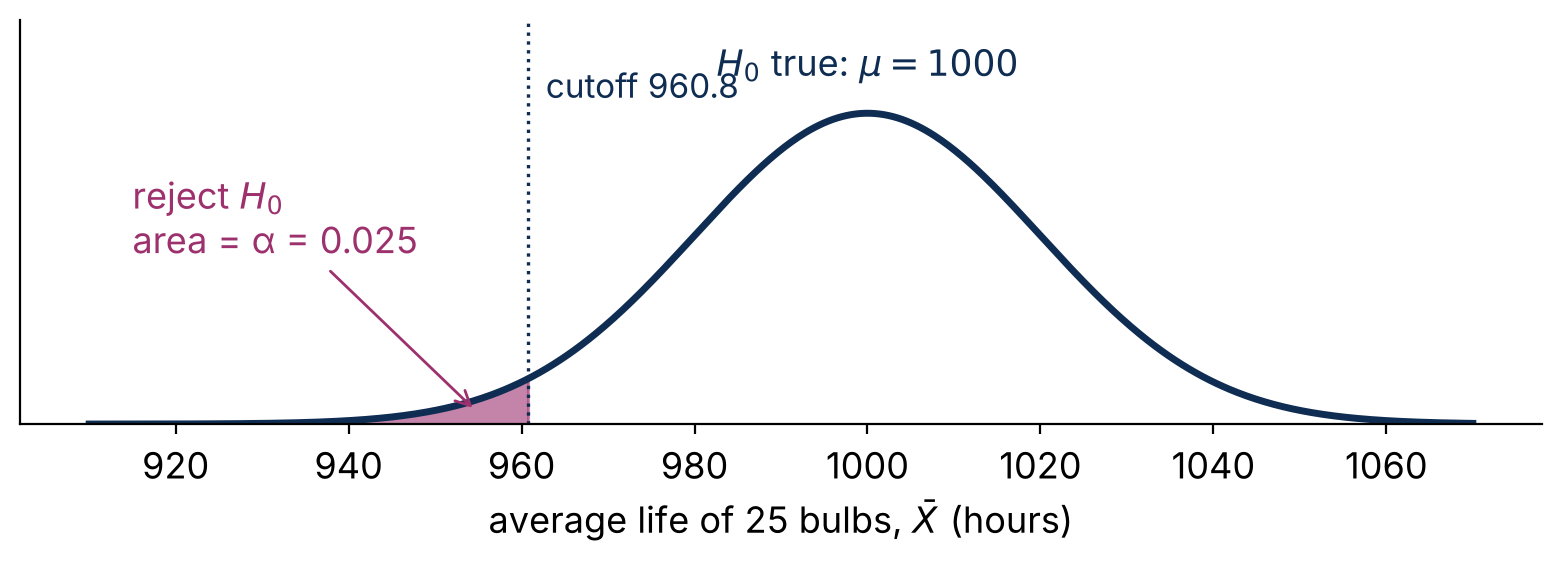

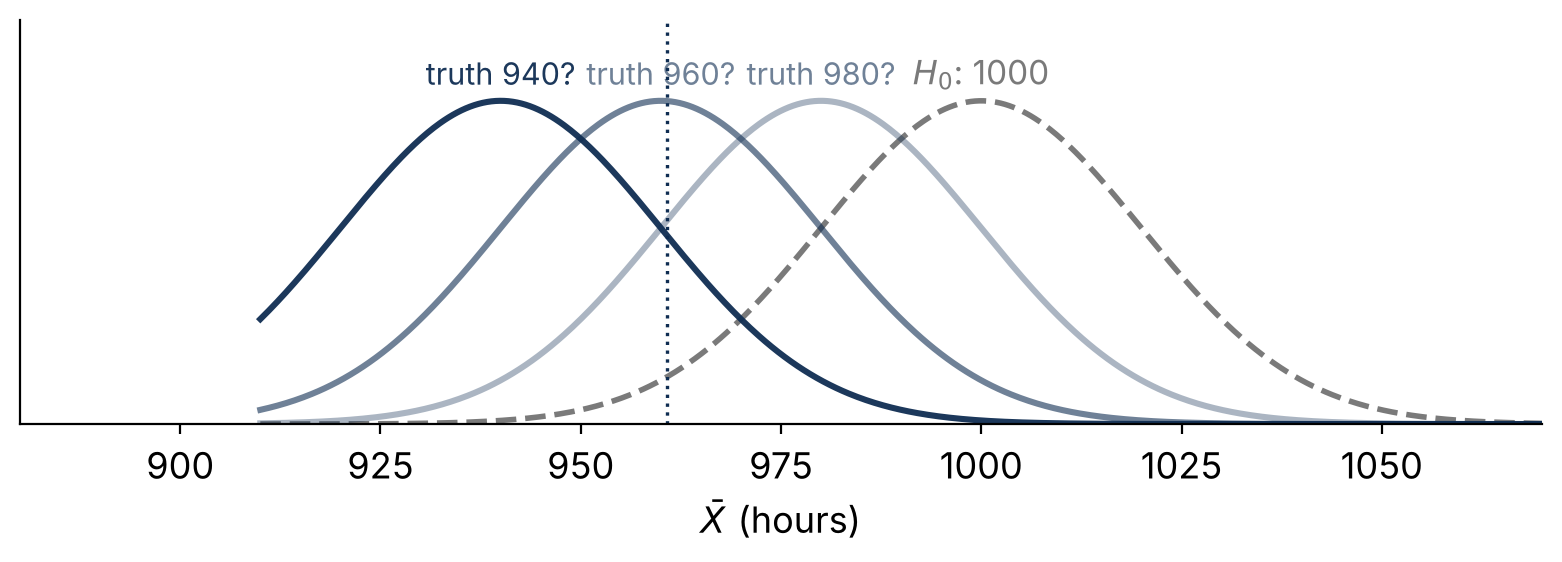

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA = 1000, 100, 0.025
Z = stats.norm.ppf(1 - ALPHA)                     # 1.96
def cutoff(n):  return MU0 - Z * SIGMA / np.sqrt(n)
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / (SIGMA / np.sqrt(n)))   # P(Xbar > c | mu)

# Type I error: the H0 picture with the rejection region (area alpha)
n = 25; se = SIGMA / np.sqrt(n); c = cutoff(n)
print(f"standard error = {se},  cutoff = {c:.2f}")
x = np.linspace(910, 1070, 600); f = stats.norm.pdf(x, MU0, se)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f, color=NAVY, lw=2.5)
ax.fill_between(x, f, where=x <= c, color=MAGENTA, alpha=0.6)
ax.axvline(c, color=NAVY, lw=1.2, ls=":")
ax.annotate("reject $H_0$\narea = α = 0.025", xy=(c - 6, f.max() * 0.04), xytext=(915, f.max() * 0.55),
            color=MAGENTA, fontsize=13, arrowprops=dict(arrowstyle="->", color=MAGENTA))
ax.text(c + 2, f.max() * 1.05, f"cutoff {c:.1f}", color=NAVY, fontsize=12)
ax.text(MU0, f.max() * 1.12, r"$H_0$ true: $\mu = 1000$", ha="center", fontsize=13, color=NAVY)
ax.set(yticks=[], xlabel=r"average life of 25 bulbs, $\bar X$ (hours)", ylim=(0, f.max() * 1.3))
save(fig, "bulbs_typeI.png")

# Why beta is harder: it depends on the TRUE mean, which we don't know
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f, color=GRAY, lw=2, ls="--")
ax.text(MU0, f.max() * 1.05, r"$H_0$: 1000", ha="center", fontsize=12, color=GRAY)
for mu, a in [(980, 0.35), (960, 0.6), (940, 0.95)]:
    g = stats.norm.pdf(x, mu, se)
    ax.plot(x, g, color=NAVY, lw=2.2, alpha=a)
    ax.text(mu, g.max() * 1.05, f"truth {mu}?", ha="center", fontsize=11, color=NAVY, alpha=max(a, 0.6))
ax.axvline(c, color=NAVY, lw=1.2, ls=":")
ax.set(yticks=[], xlabel=r"$\bar X$ (hours)", xlim=(880, 1070), ylim=(0, f.max() * 1.25))
x2 = np.linspace(880, 1070, 600)
save(fig, "possible_truths.png")


## Computing $\beta$ when the truth is $\mu = 940$

$\beta = P(\bar X > 960.8 \mid \mu = 940) = P\left(Z > \frac{960.8 - 940}{20}\right) = P(Z > 1.04) = 0.1492$.

**Try it:** change `mu_true` to 970 (the "Your Turn" on the slides).

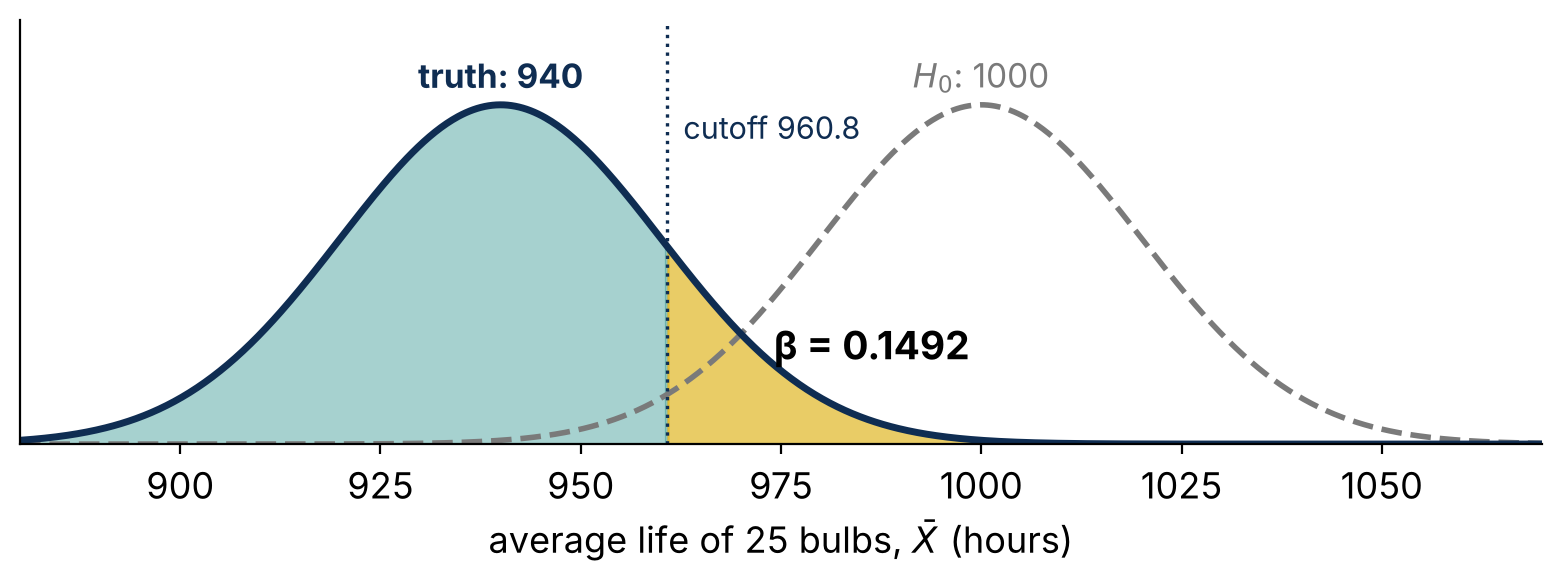

z = 1.04,  beta = 0.1492


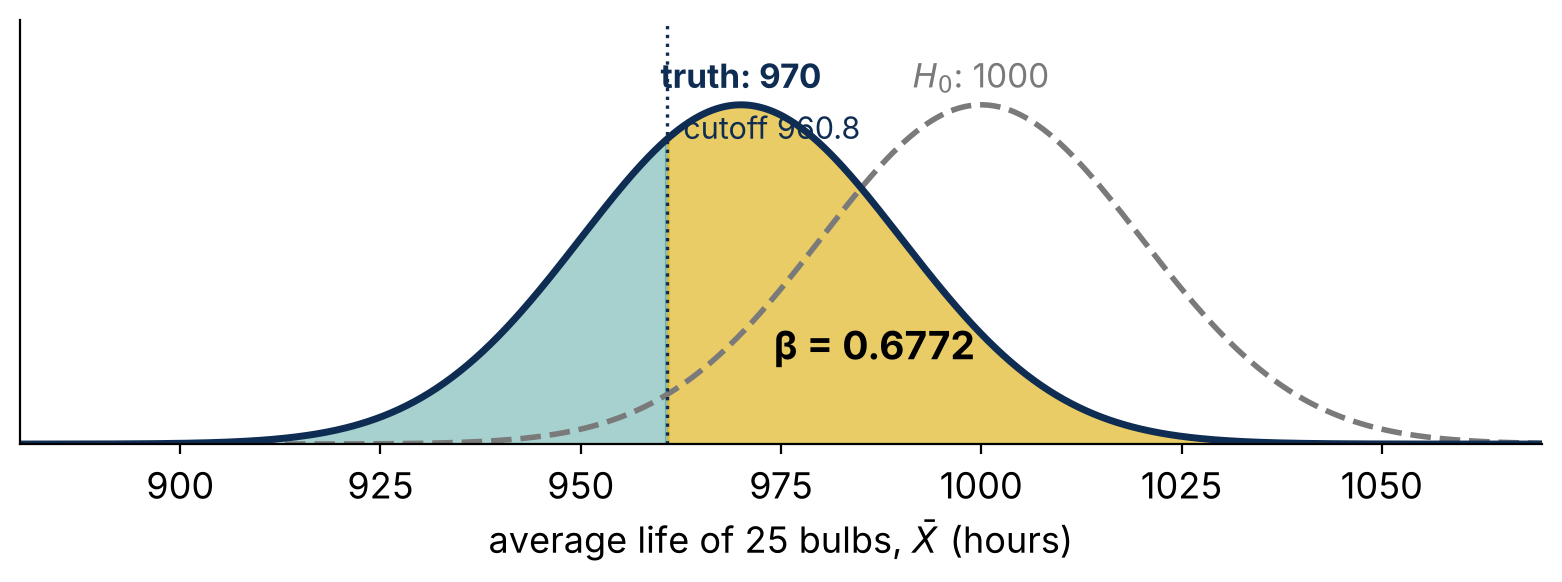

Your Turn (mu = 970): beta = 0.6772


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA = 1000, 100, 0.025
Z = stats.norm.ppf(1 - ALPHA)                     # 1.96
def cutoff(n):  return MU0 - Z * SIGMA / np.sqrt(n)
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / (SIGMA / np.sqrt(n)))   # P(Xbar > c | mu)

# beta for one true mean, with the picture
def beta_picture(n, mu_true, name, xlim=(880, 1070)):
    se = SIGMA / np.sqrt(n); c = cutoff(n); b = beta(mu_true, n)
    x = np.linspace(*xlim, 800)
    f0, f1 = stats.norm.pdf(x, MU0, se), stats.norm.pdf(x, mu_true, se)
    fig, ax = plt.subplots(figsize=(8, 3.1))
    ax.plot(x, f0, color=GRAY, lw=2, ls="--")
    ax.plot(x, f1, color=NAVY, lw=2.5)
    ax.fill_between(x, f1, where=x > c, color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=x <= c, color=TEAL, alpha=0.35)
    ax.axvline(c, color=NAVY, lw=1.2, ls=":")
    ax.text(MU0, f0.max() * 1.05, r"$H_0$: 1000", ha="center", fontsize=12, color=GRAY)
    ax.text(mu_true, f1.max() * 1.05, f"truth: {mu_true}", ha="center", fontsize=12, color=NAVY, fontweight="bold")
    ax.text(c + 2, f1.max() * 0.9, f"cutoff {c:.1f}", fontsize=11, color=NAVY)
    if b > 0.08:
        ax.text(c + (xlim[1] - xlim[0]) * 0.07, f1.max() * 0.25, f"β = {b:.4f}", fontsize=14, fontweight="bold")
    else:
        ax.annotate(f"β = {b:.4f}", xy=(c + 3, f1.max() * 0.02), xytext=(c + (xlim[1] - xlim[0]) * 0.12, f1.max() * 0.45),
                    fontsize=14, fontweight="bold", arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set(yticks=[], xlabel=rf"average life of {n} bulbs, $\bar X$ (hours)", xlim=xlim,
           ylim=(0, max(f0.max(), f1.max()) * 1.25))
    save(fig, name)
    return b

mu_true = 940
print(f"z = {(cutoff(25) - mu_true) / 20:.2f},  beta = {beta_picture(25, mu_true, 'bulbs_beta_940.png'):.4f}")
print(f"Your Turn (mu = 970): beta = {beta_picture(25, 970, 'bulbs_beta_970.png'):.4f}")


## $\beta$ depends on the truth: the power curve

The farther the truth is from $H_0$, the easier it is to catch. More data ($n = 100$) shrinks $\beta$ for every truth.

truth 980: z = -0.96,  beta = 0.8315,  power = 0.1685
truth 960: z = +0.04,  beta = 0.4840,  power = 0.5160
truth 940: z = +1.04,  beta = 0.1492,  power = 0.8508
truth 920: z = +2.04,  beta = 0.0207,  power = 0.9793


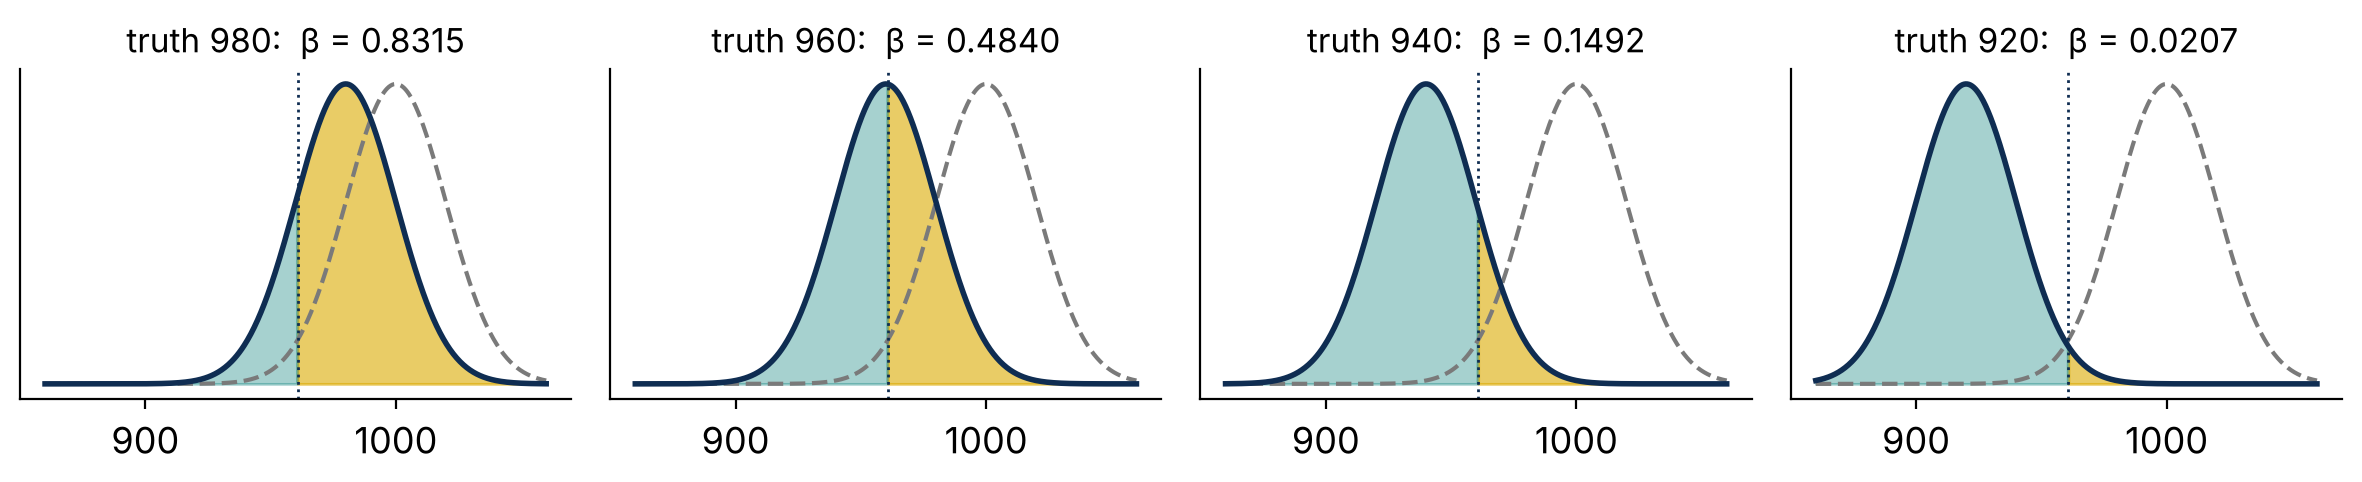

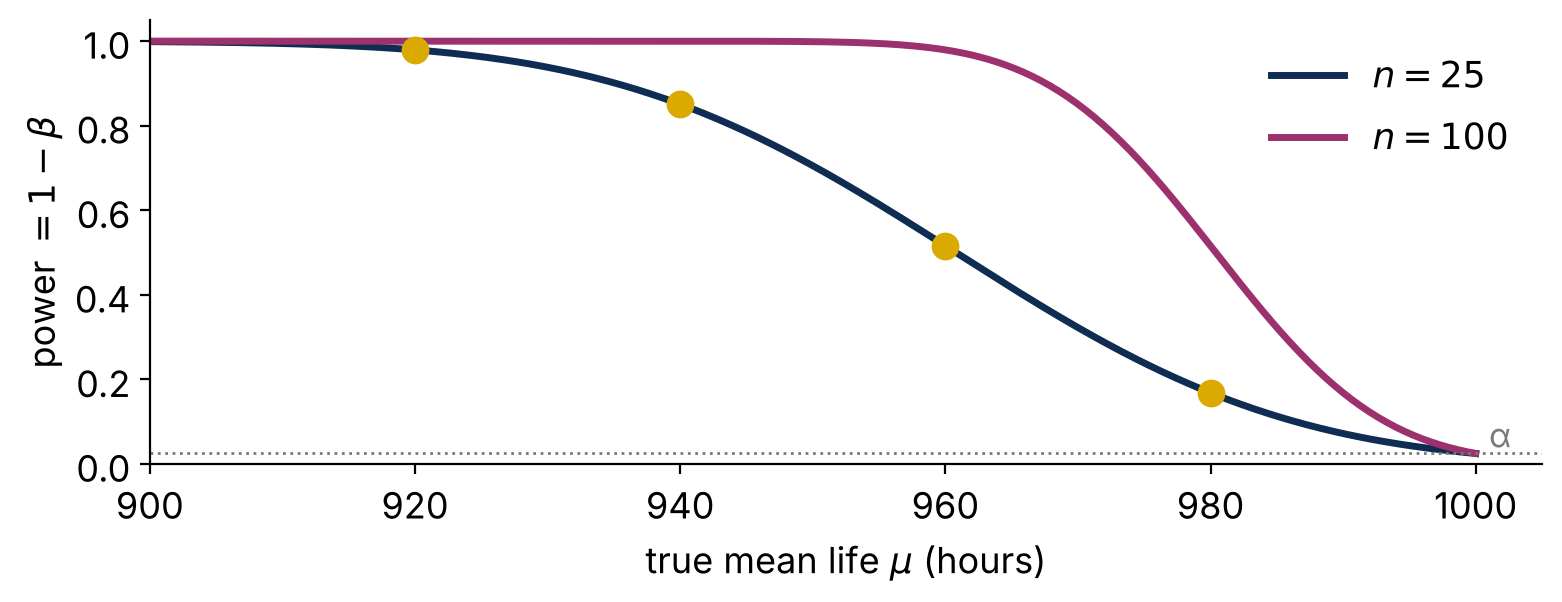

n = 100: cutoff = 980.4, beta at 960 = 0.0207


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA = 1000, 100, 0.025
Z = stats.norm.ppf(1 - ALPHA)                     # 1.96
def cutoff(n):  return MU0 - Z * SIGMA / np.sqrt(n)
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / (SIGMA / np.sqrt(n)))   # P(Xbar > c | mu)

# beta for several truths (n = 25), and the power curve for n = 25 and n = 100
truths = [980, 960, 940, 920]
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharey=True)
se = 20; c = cutoff(25); x = np.linspace(860, 1060, 600)
for ax, mu in zip(axes, truths):
    f0, f1 = stats.norm.pdf(x, MU0, se), stats.norm.pdf(x, mu, se)
    ax.plot(x, f0, color=GRAY, lw=1.5, ls="--"); ax.plot(x, f1, color=NAVY, lw=2)
    ax.fill_between(x, f1, where=x > c, color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=x <= c, color=TEAL, alpha=0.35)
    ax.axvline(c, color=NAVY, lw=1, ls=":")
    ax.set_title(f"truth {mu}:  β = {beta(mu, 25):.4f}", fontsize=12)
    ax.set_yticks([]); ax.set_xticks([900, 1000])
for mu in truths:
    print(f"truth {mu}: z = {(c - mu) / se:+.2f},  beta = {beta(mu, 25):.4f},  power = {1 - beta(mu, 25):.4f}")
save(fig, "bulbs_beta_grid.png")

mus = np.linspace(900, 1000, 300)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(mus, 1 - beta(mus, 25), color=NAVY, lw=2.5, label=r"$n = 25$")
ax.plot(mus, 1 - beta(mus, 100), color=MAGENTA, lw=2.5, label=r"$n = 100$")
for mu in truths:
    ax.plot(mu, 1 - beta(mu, 25), "o", color=GOLD, ms=9, zorder=3)
ax.axhline(0.025, color=GRAY, ls=":", lw=1); ax.text(1001, 0.04, "α", color=GRAY, fontsize=12)
ax.set(xlabel=r"true mean life $\mu$ (hours)", ylabel=r"power $= 1 - \beta$", ylim=(0, 1.05), xlim=(900, 1005))
ax.legend(frameon=False, loc="upper right")
save(fig, "power_curve.png")
print(f"n = 100: cutoff = {cutoff(100):.1f}, beta at 960 = {beta(960, 100):.4f}")


## More data, a two-sided test, and planning a study

* $n = 100$: cutoff $= 1000 - 1.96 \cdot 10 = 980.4$, and $\beta(960) = P(Z > 2.04) = 0.0207$ (it was $0.4840$ with $n = 25$).
* Two-sided at $\alpha = 0.05$: cutoffs $960.8$ and $1039.2$. When the truth is $940$, the far cutoff hardly matters.
* How many bulbs for power $0.90$ when $\mu = 960$? Solve $1000 - 1.96\,\mathrm{SE} - 960 = -1.28\,\mathrm{SE}$: $\mathrm{SE} = 40/3.24$, $\sqrt n = 8.1$, $n = 66$.

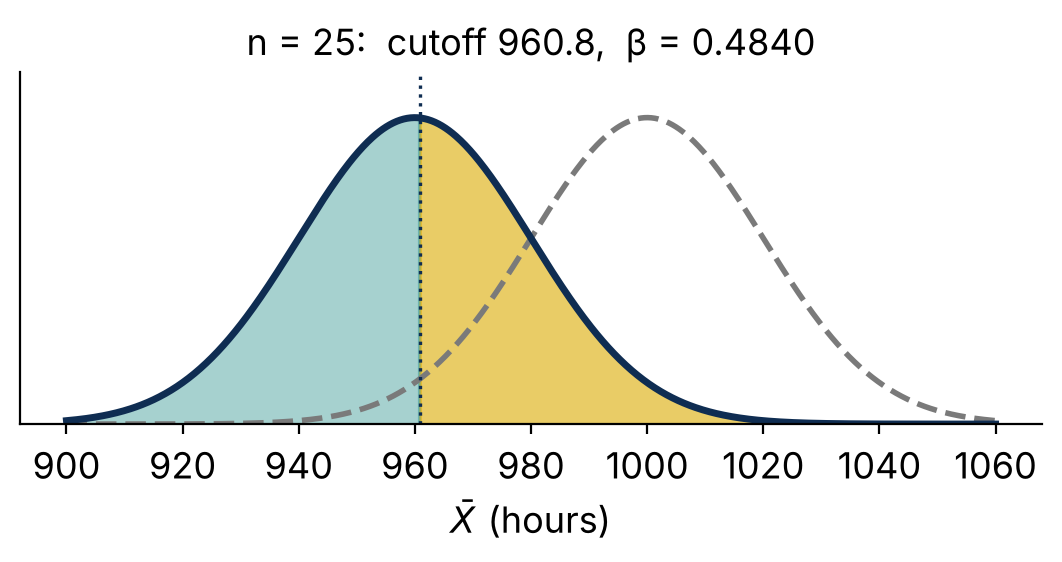

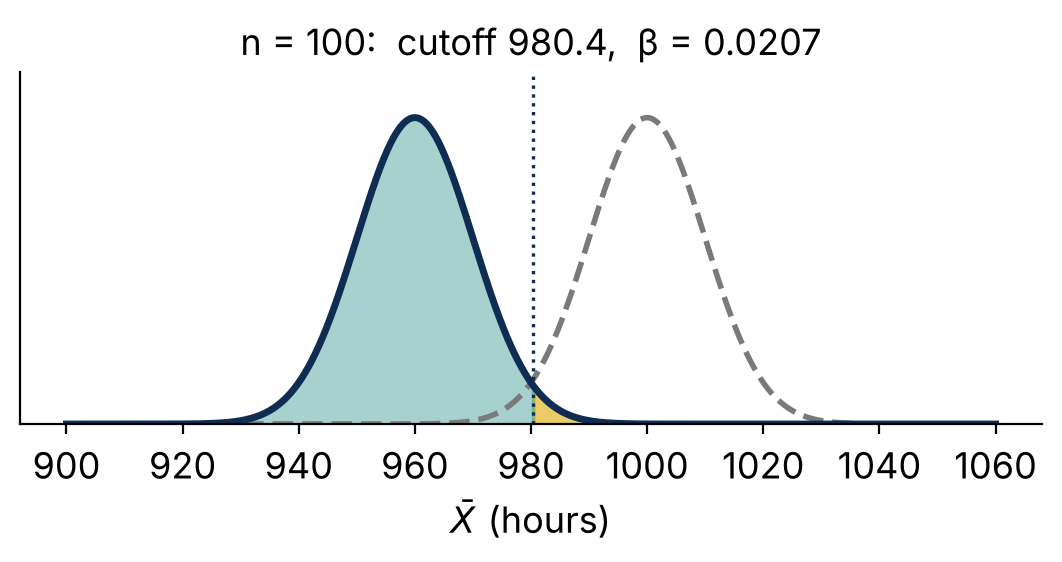

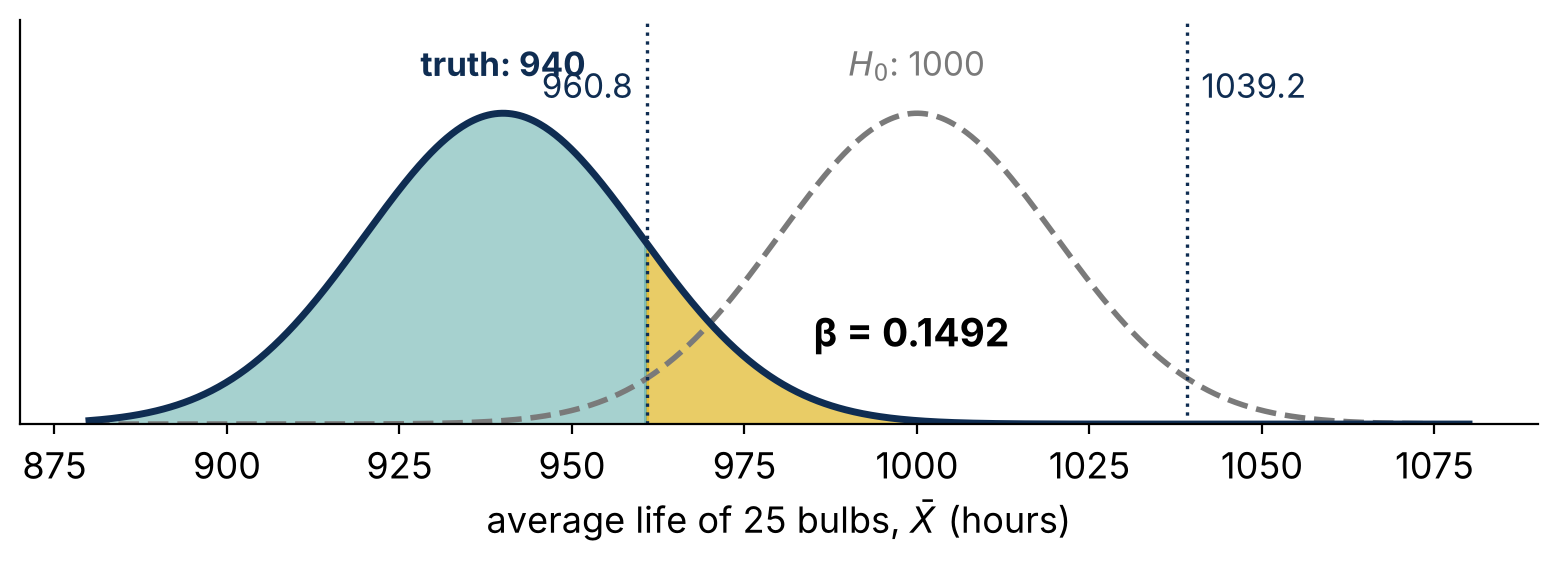

two-sided: cutoffs (960.8, 1039.2), beta at 940 = 0.1492
n needed: 66  power with that n: 0.9014


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA = 1000, 100, 0.025
Z = stats.norm.ppf(1 - ALPHA)                     # 1.96
def cutoff(n):  return MU0 - Z * SIGMA / np.sqrt(n)
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / (SIGMA / np.sqrt(n)))   # P(Xbar > c | mu)

# n = 25 vs n = 100 at truth 960 (same x-axis)
for n, name in [(25, "bulbs_n25_960.png"), (100, "bulbs_n100_960.png")]:
    se = SIGMA / np.sqrt(n); c = cutoff(n); x = np.linspace(900, 1060, 800)
    f0, f1 = stats.norm.pdf(x, MU0, se), stats.norm.pdf(x, 960, se)
    fig, ax = plt.subplots(figsize=(5.5, 3.0))
    ax.plot(x, f0, color=GRAY, lw=2, ls="--"); ax.plot(x, f1, color=NAVY, lw=2.5)
    ax.fill_between(x, f1, where=x > c, color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=x <= c, color=TEAL, alpha=0.35)
    ax.axvline(c, color=NAVY, lw=1.2, ls=":")
    ax.set_title(f"n = {n}:  cutoff {c:.1f},  β = {beta(960, n):.4f}", fontsize=13)
    ax.set(yticks=[], xlabel=r"$\bar X$ (hours)", ylim=(0, max(f0.max(), f1.max()) * 1.15))
    save(fig, name)

# two-sided test at alpha = 0.05, truth 940
se = 20; lo, hi = 1000 - 1.96 * se, 1000 + 1.96 * se; x = np.linspace(880, 1080, 800)
f0, f1 = stats.norm.pdf(x, MU0, se), stats.norm.pdf(x, 940, se)
b2 = stats.norm.cdf(hi, 940, se) - stats.norm.cdf(lo, 940, se)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f0, color=GRAY, lw=2, ls="--"); ax.plot(x, f1, color=NAVY, lw=2.5)
ax.fill_between(x, f1, where=(x > lo) & (x < hi), color=GOLD, alpha=0.6)
ax.fill_between(x, f1, where=(x <= lo), color=TEAL, alpha=0.35)
for cc in (lo, hi): ax.axvline(cc, color=NAVY, lw=1.2, ls=":")
ax.text(lo - 2, f1.max() * 1.05, f"{lo:.1f}", ha="right", fontsize=12, color=NAVY)
ax.text(hi + 2, f1.max() * 1.05, f"{hi:.1f}", ha="left", fontsize=12, color=NAVY)
ax.text(MU0, f0.max() * 1.12, r"$H_0$: 1000", ha="center", fontsize=12, color=GRAY)
ax.text(940, f1.max() * 1.12, "truth: 940", ha="center", fontsize=12, color=NAVY, fontweight="bold")
ax.text(985, f1.max() * 0.25, f"β = {b2:.4f}", fontsize=14, fontweight="bold")
ax.set(yticks=[], xlabel=r"average life of 25 bulbs, $\bar X$ (hours)", ylim=(0, f0.max() * 1.3))
save(fig, "bulbs_twosided.png")
print(f"two-sided: cutoffs ({lo:.1f}, {hi:.1f}), beta at 940 = {b2:.4f}")

# planning: smallest n with power >= 0.90 when mu = 960
n_needed = int(np.ceil((SIGMA * (1.96 + 1.28) / 40) ** 2))
print("n needed:", n_needed, " power with that n:", round(1 - beta(960, n_needed), 4))


## The story, and the punchline

**Story:** the company claims $\mu = 1000$, but behind the curtain the bulbs really last $\mu = 960$ hours.
With $n = 25$ the test misses this about half the time ($\beta = 0.4840$). With $n = 100$, $\beta = 0.0207$ — and $\alpha$ is still $0.025$.

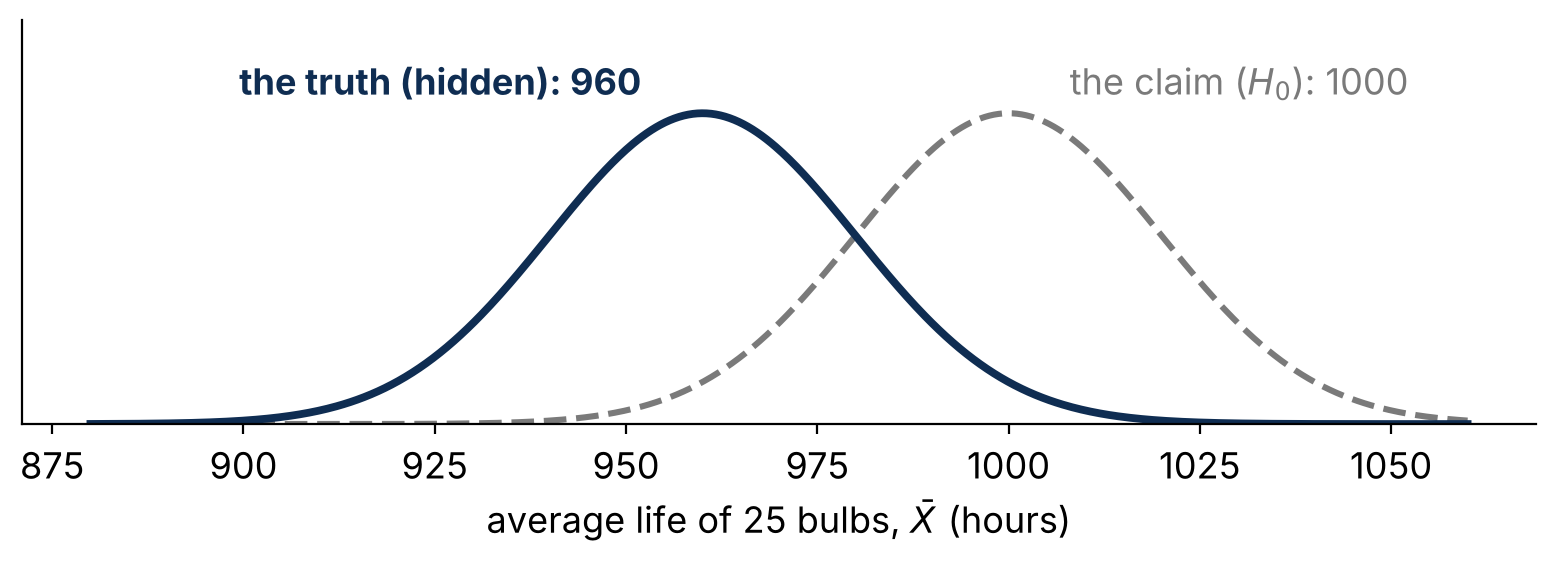

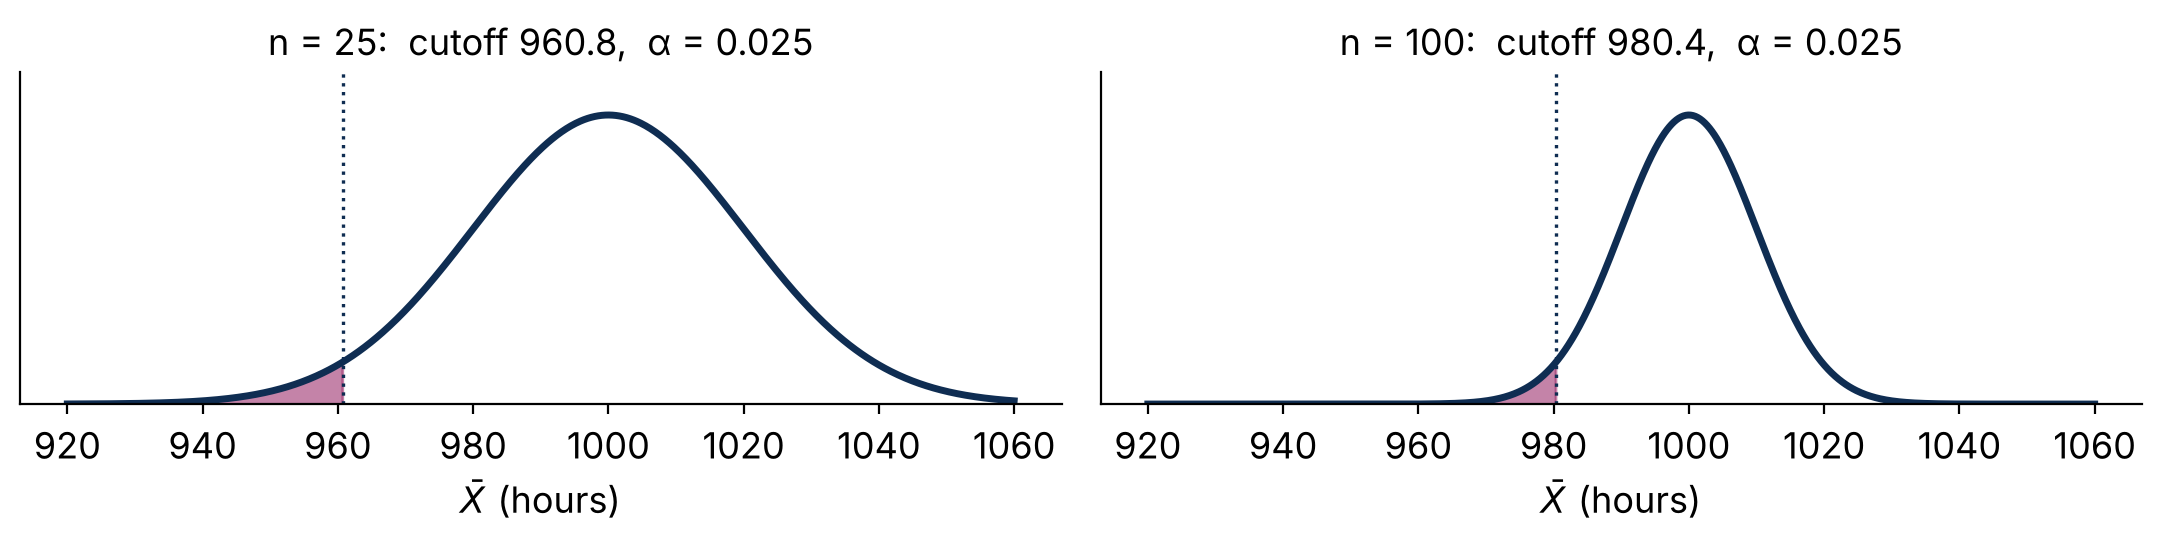

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA = 1000, 100, 0.025
Z = stats.norm.ppf(1 - ALPHA)                     # 1.96
def cutoff(n):  return MU0 - Z * SIGMA / np.sqrt(n)
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / (SIGMA / np.sqrt(n)))   # P(Xbar > c | mu)

# The story picture: what the company claims vs. the (hidden) truth
se = 20; x = np.linspace(880, 1060, 600)
f0, f1 = stats.norm.pdf(x, MU0, se), stats.norm.pdf(x, 960, se)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f0, color=GRAY, lw=2.2, ls="--"); ax.plot(x, f1, color=NAVY, lw=2.8)
ax.text(MU0 + 8, f0.max() * 1.06, "the claim ($H_0$): 1000", ha="left", fontsize=13, color=GRAY)
ax.text(960 - 8, f1.max() * 1.06, "the truth (hidden): 960", ha="right", fontsize=13, color=NAVY, fontweight="bold")
ax.set(yticks=[], xlabel=r"average life of 25 bulbs, $\bar X$ (hours)", ylim=(0, f0.max() * 1.3))
save(fig, "story.png")

# The punchline: alpha is the same for n = 25 and n = 100
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharex=True)
x = np.linspace(920, 1060, 800)
for ax, n in zip(axes, [25, 100]):
    se = SIGMA / np.sqrt(n); c = cutoff(n); f = stats.norm.pdf(x, MU0, se)
    ax.plot(x, f, color=NAVY, lw=2.5)
    ax.fill_between(x, f, where=x <= c, color=MAGENTA, alpha=0.6)
    ax.axvline(c, color=NAVY, lw=1.2, ls=":")
    ax.set_title(f"n = {n}:  cutoff {c:.1f},  α = {stats.norm.cdf(c, MU0, se):.3f}", fontsize=13)
    ax.set(yticks=[], xlabel=r"$\bar X$ (hours)", ylim=(0, f.max() * 1.15))
save(fig, "alpha_n25_n100.png")
